In [53]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUTA_INTERIM = Path("../data/interim")

carpeta_resenas = (
    RUTA_INTERIM / "resenas_videojuegos_bloques"
)

ruta_metadatos = (
    RUTA_INTERIM / "metadatos_videojuegos.parquet"
)

archivos_resenas = sorted(
    carpeta_resenas.glob("*.parquet")
)

videojuegos = pd.read_parquet(
    ruta_metadatos

)
print("Archivos de reseñas encontrados:", len(archivos_resenas))
print("Archivo de metadatos encontrado:", ruta_metadatos.exists())

Archivos de reseñas encontrados: 47
Archivo de metadatos encontrado: True


In [15]:
# 
conteo_puntuaciones = pd.Series(
    0,
    index=[1, 2, 3, 4, 5],
)

total_resenas = 0

In [16]:
for archivo in archivos_resenas:
    bloque = pd.read_parquet(
        archivo,
        columns=["rating"]
    )
    
    conteo_puntuaciones +=  bloque["rating"].value_counts()

    
    total_resenas += len(bloque)
    
porcentaje_puntuaciones = (conteo_puntuaciones / total_resenas) * 100

resumen_puntuaciones = pd.DataFrame({
    "Puntuación": conteo_puntuaciones.index,
    "Cantidad de reseñas": conteo_puntuaciones.values,
    "Porcentaje": porcentaje_puntuaciones.values.round(2).astype(str) + " %"
})

print("Total de reseñas analizadas:", total_resenas)
resumen_puntuaciones




Total de reseñas analizadas: 1502718


,Puntuación,Cantidad de reseñas,Porcentaje
0,1,168425,11.21 %
1,2,73111,4.87 %
2,3,119156,7.93 %
3,4,225616,15.01 %
4,5,916410,60.98 %


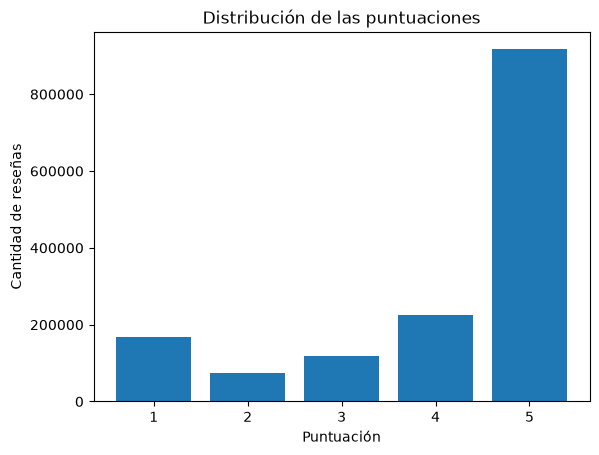

In [20]:
plt.bar(
    resumen_puntuaciones["Puntuación"],
    resumen_puntuaciones["Cantidad de reseñas"]
)

plt.title("Distribución de las puntuaciones")
plt.xlabel("Puntuación")
plt.ylabel("Cantidad de reseñas")
plt.xticks([1, 2, 3, 4, 5])
plt.show()

In [28]:
# Distribución de opiniones

from matplotlib.pylab import dtype


negativas = (
    conteo_puntuaciones.loc[1]
    + conteo_puntuaciones.loc[2]
)

neutrales = (
    conteo_puntuaciones.loc[3]
)

positivas = (
    conteo_puntuaciones.loc[4]
    + conteo_puntuaciones.loc[5]
)

conteo_opiniones = pd.Series(
    {
        "Negativas": negativas,
        "Neutrales": neutrales,
        "Positivas": positivas
    }
)
print("CONTEO DE OPINIONES:")
print("---------------------")
print(conteo_opiniones)

print("COMPROBACIÓN DE LAS OPINIONES")
print("-----------------------------")
print(
    "Total de opiniones agrupadas:",
    f"{conteo_opiniones.sum():,}"
)
print(
    "Total de reseñas analizadas:",
    f"{total_resenas:,}"
)
print(
    "¿Coinciden los resultados?",
    conteo_opiniones.sum() == total_resenas
)

CONTEO DE OPINIONES:
---------------------
Negativas     241536
Neutrales     119156
Positivas    1142026
dtype: int64
COMPROBACIÓN DE LAS OPINIONES
-----------------------------
Total de opiniones agrupadas: 1,502,718
Total de reseñas analizadas: 1,502,718
¿Coinciden los resultados? True


In [29]:
# Porcentaje de opiniones
porcentaje_opiniones = (conteo_opiniones / total_resenas) * 100

resumen_opiniones = pd.DataFrame({
    "Opinión": conteo_opiniones.index,
    "Cantidad de reseñas": conteo_opiniones.values,
    "Porcentaje": porcentaje_opiniones.values.round(2).astype(str) + " %"
})

resumen_opiniones

,Opinión,Cantidad de reseñas,Porcentaje
0,Negativas,241536,16.07 %
1,Neutrales,119156,7.93 %
2,Positivas,1142026,76.0 %


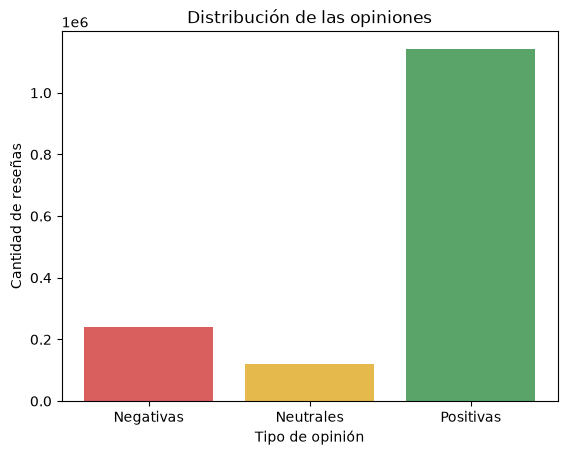

In [40]:
# Grafico de opiniones
plt.bar(
    resumen_opiniones["Opinión"],
    resumen_opiniones["Cantidad de reseñas"],
    color=["#D95F5F", "#E5B94B", "#5AA469"]
)

plt.title("Distribución de las opiniones")
plt.xlabel("Tipo de opinión")
plt.ylabel("Cantidad de reseñas")

plt.show()


In [46]:
#Distribución de reseñas por juego

conteo_resenas_por_videojuego = pd.Series(dtype="int64")

for archivo in archivos_resenas:
    bloque = pd.read_parquet(
        archivo,
        columns=["parent_asin"]
    )
    
    conteo_resenas_por_videojuego = (
        conteo_resenas_por_videojuego
        .add(bloque["parent_asin"].value_counts(), fill_value=0)
    )


print("COMPROBACIÓN DEL RECUENTO")
print("-------------------------")
print(
    "Videojuegos con reseñas:",
    f"{len(conteo_resenas_por_videojuego):,}"
)
print(
    "Total de reseñas contabilizadas:",
    f"{conteo_resenas_por_videojuego.sum():,}"
)
print(
    "Total esperado:",
    f"{total_resenas:,}"
)
print(
    "¿Coinciden los resultados?",
    conteo_resenas_por_videojuego.sum() == total_resenas
)

COMPROBACIÓN DEL RECUENTO
-------------------------
Videojuegos con reseñas: 46,528
Total de reseñas contabilizadas: 1,502,718.0
Total esperado: 1,502,718
¿Coinciden los resultados? True


In [49]:
estadisticas_resenas_por_videojuego = conteo_resenas_por_videojuego.describe()

media_resenas = conteo_resenas_por_videojuego.mean()
mediana_resenas = conteo_resenas_por_videojuego.median()
minimo_resenas = conteo_resenas_por_videojuego.min()
maximo_resenas = conteo_resenas_por_videojuego.max()

print("RESEÑAS POR VIDEOJUEGO")
print("----------------------")
print(
    "Número de videojuegos:",
    f"{len(conteo_resenas_por_videojuego):,}"
)
print(f"Media de reseñas: {media_resenas:,.2f}")
print(f"Mediana de reseñas: {mediana_resenas:,.0f}")
print(f"Mínimo de reseñas: {minimo_resenas:,}")
print(f"Máximo de reseñas: {maximo_resenas:,}")

RESEÑAS POR VIDEOJUEGO
----------------------
Número de videojuegos: 46,528
Media de reseñas: 32.30
Mediana de reseñas: 4
Mínimo de reseñas: 1.0
Máximo de reseñas: 12,100.0


In [63]:
# Videojuegos con menos reseñas 
ranking_videojuegos = (
    conteo_resenas_por_videojuego
    .rename("numero_resenas")
    .reset_index()
    .rename(columns={"index": "parent_asin"})
)

ranking_videojuegos = ranking_videojuegos.merge(
    videojuegos
    [
        [
            "parent_asin",
            "product_title",
            "categories"
        ]
    ],
    on="parent_asin",
    how="left",
    validate="one_to_one"
)



In [71]:
# Videojuegos con más reseñas
top_videojuegos = ranking_videojuegos[
    [
        "product_title",
        "parent_asin",
        "numero_resenas"
    ]
].nlargest(10, "numero_resenas")

print("TOP 10 VIDEOJUEGOS CON MÁS RESEÑAS")
print("----------------------------------")
top_videojuegos


TOP 10 VIDEOJUEGOS CON MÁS RESEÑAS
----------------------------------


,product_title,parent_asin,numero_resenas
26881,Grand Theft Auto V: Premium Edition - Xbox One...,B0086VPUHI,12100.0
42097,Skyrim VR - PlayStation 4,B07YBXFDYN,9430.0
42082,Fallout 4 - Xbox One,B07YBWT3PK,7202.0
28891,Battlefield 4 - Playstation 3,B00C1TTF86,6216.0
25372,American Sniper: The Autobiography of the Most...,B005GFPZYK,6051.0
29780,The Sims 4 - Movie Hangout Stuff - Origin PC [...,B00EP2WNKY,5161.0
29091,Call of Duty Ghosts - PS3 [Digital Code],B00CJ9OTNE,5109.0
28726,Assassin's Creed IV Black Flag - PC,B00BN5T30E,4771.0
24013,Battlefield 3 - Playstation 3,B004LLHFAW,4407.0
30776,"Ferrero Rocher, Premium Gourmet Milk Chocolate...",B00HBUOVIO,4354.0


In [72]:
# Videojuegos con menos reseñas
top2_videojuegos = ranking_videojuegos[
    [
        "product_title",
        "parent_asin",
        "numero_resenas"
    ]
].sort_values(by="numero_resenas").head(10)

print("TOP 10 VIDEOJUEGOS CON MENOS RESEÑAS")
print("----------------------------------")
top2_videojuegos


TOP 10 VIDEOJUEGOS CON MENOS RESEÑAS
----------------------------------


,product_title,parent_asin,numero_resenas
28167,Pokemon - Diamond Version,B00AKG85U6,1.0
46505,yuja vita sun cream,B0CBLBQJ42,1.0
24,Thomas & Friends: Great Festival Adventure!,0439374391,1.0
39076,Owlboy Limited Edition (Nintendo Switch),B07CZ8YVQ8,1.0
39075,Lego Star Wars Force Awakens (PS3),B07CZ5BZC4,1.0
39073,Watch Dogs 2 PS4 - Plays In English 100% Dobla...,B07CYRD2HS,1.0
39072,Pogba (Ultimate Football Heroes - Limited Inte...,B07CYLBZT5,1.0
12427,Bode Miller Alpine Skiing - PC,B000ELBYAA,1.0
12426,Gem Smashers,B000EKETRG,1.0
12425,Buzby Breakin' All The Rules Hermie and Friends,B000EK6EKQ,1.0


In [83]:
# videojuegos intervalos
videojuegos_una_resena = (
    conteo_resenas_por_videojuego == 1
).sum()

videojuegos_hasta_5 = (
    (conteo_resenas_por_videojuego > 1)
    & (conteo_resenas_por_videojuego <= 5)
).sum()

videojuegos_hasta_10 = (
    (conteo_resenas_por_videojuego > 5)
    & (conteo_resenas_por_videojuego <= 10)
).sum()

videojuegos_hasta_100 = (
    (conteo_resenas_por_videojuego > 10)
    & (conteo_resenas_por_videojuego <= 100)
).sum()

videojuegos_hasta_1000 = (
    (conteo_resenas_por_videojuego > 100)
    & (conteo_resenas_por_videojuego <= 1000)
).sum()

videojuegos_mas_1000 = (
    (conteo_resenas_por_videojuego > 1000)
).sum()

print("DISTRIBUCIÓN POR INTERVALOS")
print("--------------------------")
print(
    "Videojuegos con 1 reseña:",
    f"{videojuegos_una_resena:,}"
)
print(
    "Videojuegos con hasta 5 reseñas:",
    f"{videojuegos_hasta_5:,}"
)
print(
    "Videojuegos con hasta 10 reseñas:",
    f"{videojuegos_hasta_10:,}"
)
print(
    "Videojuegos con hasta 100 reseñas:",
    f"{videojuegos_hasta_100:,}"
)
print(
    "Videojuegos con hasta 1.000 reseñas:",
    f"{videojuegos_hasta_1000:,}"
)

print(
    "Videojuegos con más de 1.000 reseñas:",
    f"{videojuegos_mas_1000:,}"
)

print(
    "Videjuegs totales:",
    f"{len(conteo_resenas_por_videojuego):,}"
)

DISTRIBUCIÓN POR INTERVALOS
--------------------------
Videojuegos con 1 reseña: 12,410
Videojuegos con hasta 5 reseñas: 14,179
Videojuegos con hasta 10 reseñas: 5,835
Videojuegos con hasta 100 reseñas: 11,376
Videojuegos con hasta 1.000 reseñas: 2,544
Videojuegos con más de 1.000 reseñas: 184
Videjuegs totales: 46,528


In [86]:
# Gráfico de distribución de reseñas por juego
total_intervalos = (
    videojuegos_una_resena
    + videojuegos_hasta_5
    + videojuegos_hasta_10
    + videojuegos_hasta_100
    + videojuegos_hasta_1000
    + videojuegos_mas_1000
)

total_videojuegos = len(
    conteo_resenas_por_videojuego
)

print("\nCOMPROBACIÓN")
print("------------")
print(f"Videojuegos en los intervalos: {total_intervalos:,}")
print(f"Videojuegos esperados: {total_videojuegos:,}")
print(
    "¿Cada videojuego aparece una sola vez?",
    total_intervalos == total_videojuegos
)

resumen_intervalos = pd.DataFrame({
    "Intervalo": [
        "1 reseña",
        "De 2 a 5",
        "De 6 a 10",
        "De 11 a 100",
        "De 101 a 1.000",
        "Más de 1.000"
    ],
    "Número de videojuegos": [
        videojuegos_una_resena,
        videojuegos_hasta_5,
        videojuegos_hasta_10,
        videojuegos_hasta_100,
        videojuegos_hasta_1000,
        videojuegos_mas_1000
    ]
})

resumen_intervalos["Porcentaje"] = (
    resumen_intervalos["Número de videojuegos"]
    / total_videojuegos
    * 100
).round(2).astype(str) + " %"

resumen_intervalos


COMPROBACIÓN
------------
Videojuegos en los intervalos: 46,528
Videojuegos esperados: 46,528
¿Cada videojuego aparece una sola vez? True


,Intervalo,Número de videojuegos,Porcentaje
0,1 reseña,12410,26.67 %
1,De 2 a 5,14179,30.47 %
2,De 6 a 10,5835,12.54 %
3,De 11 a 100,11376,24.45 %
4,De 101 a 1.000,2544,5.47 %
5,Más de 1.000,184,0.4 %


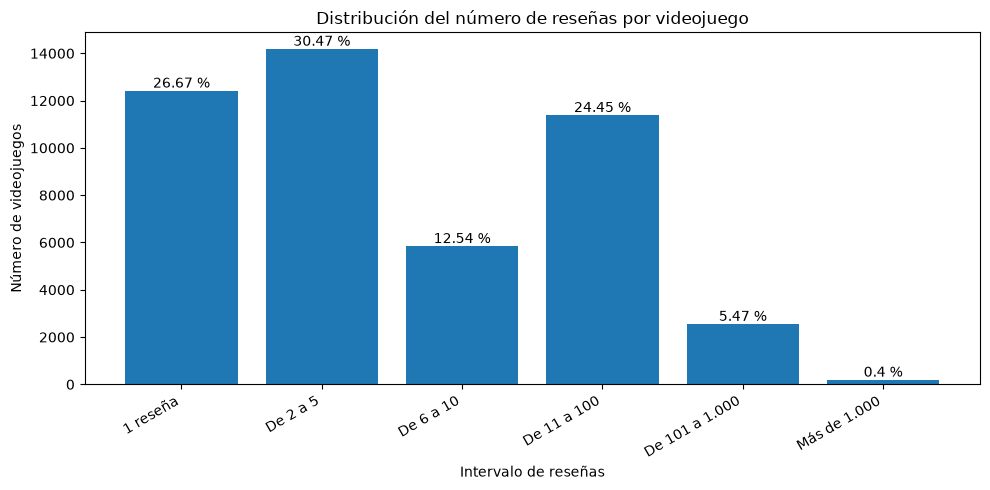

In [91]:
plt.figure(figsize=(10, 5))

barras = plt.bar(
    resumen_intervalos["Intervalo"],
    resumen_intervalos["Número de videojuegos"]
)

plt.title("Distribución del número de reseñas por videojuego")
plt.xlabel("Intervalo de reseñas")
plt.ylabel("Número de videojuegos")
plt.xticks(rotation=30, ha="right")

for barra, porcentaje in zip(
    barras,
    resumen_intervalos["Porcentaje"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        porcentaje,
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [ ]:
# Longitud de las reseñas

longitudes_bloques = []

for archivo in archivos_resenas:
    bloque = pd.read_parquet(
        archivo,
        columns=["text"]
    )

    longitud_bloque = pd.DataFrame({
        "numero_caracteres": (
            bloque["text"].str.len()
        ),
        "numero_palabras": (
            bloque["text"].str.split().str.len()
        )
    })

    longitudes_bloques.append(
        longitud_bloque
    )
longitudes_resenas = pd.concat(
    longitudes_bloques,
    ignore_index=True
)
    
print("COMPROBACIÓN DE LONGITUDES")
print("-------------------------")
print(
    "Reseñas analizadas:",
    f"{len(longitudes_resenas):,}"
)
print(
    "Reseñas esperadas:",
    f"{total_resenas:,}"
)
print(
    "¿Coinciden?",
    len(longitudes_resenas) == total_resenas
)



COMPROBACIÓN DE LONGITUDES
-------------------------
Reseñas analizadas: 1,502,718
Reseñas esperadas: 1,502,718
¿Coinciden? True


,numero_caracteres,numero_palabras
count,1502718.00,1502718.00
mean,408.16,74.71
std,894.98,159.29
min,0.00,0.00
25%,44.00,8.00
50%,136.00,26.00
75%,373.00,70.00
max,36893.00,5988.00


In [98]:
estadisticas_longitud = (
    longitudes_resenas[
        [
            "numero_caracteres",
            "numero_palabras"
        ]
    ]
    .describe()
    .round(2)
)

estadisticas_longitud


,numero_caracteres,numero_palabras
count,1502718.00,1502718.00
mean,408.16,74.71
std,894.98,159.29
min,0.00,0.00
25%,44.00,8.00
50%,136.00,26.00
75%,373.00,70.00
max,36893.00,5988.00


In [100]:
print("LONGITUD DE LAS RESEÑAS")
print("-----------------------")
print(
    "Media de palabras:",
    f"{longitudes_resenas['numero_palabras'].mean():,.2f}"
)
print(
    "Mediana de palabras:",
    f"{longitudes_resenas['numero_palabras'].median():,.0f}"
)
print(
    "Mínimo de palabras:",
    f"{longitudes_resenas['numero_palabras'].min():,}"
)
print(
    "Máximo de palabras:",
    f"{longitudes_resenas['numero_palabras'].max():,}"
)

LONGITUD DE LAS RESEÑAS
-----------------------
Media de palabras: 74.71
Mediana de palabras: 26
Mínimo de palabras: 0
Máximo de palabras: 5,988


In [101]:
print("LONGITUD DE LAS RESEÑAS")
print("-----------------------")
print(
    "Media de palabras:",
    f"{longitudes_resenas['numero_palabras'].mean():,.2f}"
)
print(
    "Mediana de palabras:",
    f"{longitudes_resenas['numero_palabras'].median():,.0f}"
)
print(
    "Mínimo de palabras:",
    f"{longitudes_resenas['numero_palabras'].min():,}"
)
print(
    "Máximo de palabras:",
    f"{longitudes_resenas['numero_palabras'].max():,}"
)

LONGITUD DE LAS RESEÑAS
-----------------------
Media de palabras: 74.71
Mediana de palabras: 26
Mínimo de palabras: 0
Máximo de palabras: 5,988


In [102]:
intervalos_longitud = pd.cut(
    longitudes_resenas["numero_palabras"],
    bins=[0, 5, 10, 25, 50, 100, 250, float("inf")],
    labels=[
        "De 1 a 5",
        "De 6 a 10",
        "De 11 a 25",
        "De 26 a 50",
        "De 51 a 100",
        "De 101 a 250",
        "Más de 250"
    ],
    include_lowest=True
)

In [103]:
conteo_intervalos_longitud = (
    intervalos_longitud
    .value_counts()
    .sort_index()
)

resumen_longitudes = pd.DataFrame({
    "Longitud en palabras": (
        conteo_intervalos_longitud.index.astype(str)
    ),
    "Número de reseñas": (
        conteo_intervalos_longitud.to_numpy()
    )
})

resumen_longitudes["Porcentaje"] = (
    resumen_longitudes["Número de reseñas"]
    / len(longitudes_resenas)
    * 100
).round(2)

resumen_longitudes

,Longitud en palabras,Número de reseñas,Porcentaje
0,De 1 a 5,283794,18.89
1,De 6 a 10,148319,9.87
2,De 11 a 25,312458,20.79
3,De 26 a 50,275794,18.35
4,De 51 a 100,207222,13.79
5,De 101 a 250,174230,11.59
6,Más de 250,100901,6.71


In [104]:
print("COMPROBACIÓN DE LOS INTERVALOS")
print("------------------------------")
print(
    "Reseñas contabilizadas:",
    f"{resumen_longitudes['Número de reseñas'].sum():,}"
)
print(
    "Reseñas esperadas:",
    f"{len(longitudes_resenas):,}"
)
print(
    "¿Cada reseña aparece una sola vez?",
    resumen_longitudes["Número de reseñas"].sum()
    == len(longitudes_resenas)
)

COMPROBACIÓN DE LOS INTERVALOS
------------------------------
Reseñas contabilizadas: 1,502,718
Reseñas esperadas: 1,502,718
¿Cada reseña aparece una sola vez? True


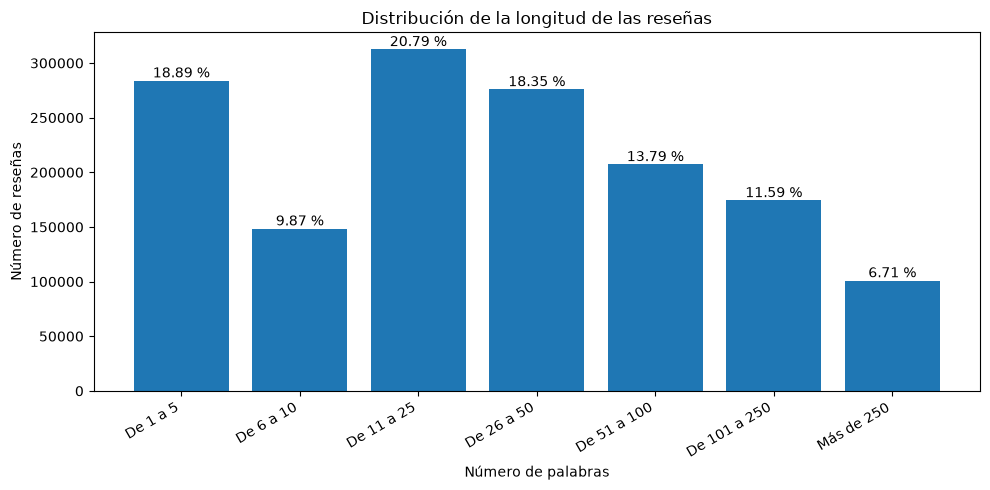

In [105]:
plt.figure(figsize=(10, 5))

barras = plt.bar(
    resumen_longitudes["Longitud en palabras"],
    resumen_longitudes["Número de reseñas"]
)

plt.title("Distribución de la longitud de las reseñas")
plt.xlabel("Número de palabras")
plt.ylabel("Número de reseñas")
plt.xticks(rotation=30, ha="right")

for barra, porcentaje in zip(
    barras,
    resumen_longitudes["Porcentaje"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{porcentaje:.2f} %",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [111]:
# Evolución temporal de las reseñas
conteo_resenas_tiempo= pd.Series(dtype="int64")
fechas_no_validas = 0

for archivo in archivos_resenas:
    bloque = pd.read_parquet(
        archivo,
        columns=["timestamp"]
    )

    fechas = pd.to_datetime(
        bloque["timestamp"],
        errors="coerce"
    )

    fechas_no_validas += fechas.isna().sum()

    anos_bloque = fechas.dt.year.value_counts()

    conteo_resenas_tiempo = (
        conteo_resenas_tiempo.add(
            anos_bloque,
            fill_value=0
        )
    )

In [112]:
conteo_resenas_tiempo= (
    conteo_resenas_tiempo
    .astype("int64")
    .sort_index()
)

total_fechas_validas = conteo_resenas_tiempo.sum()

print("COMPROBACIÓN TEMPORAL")
print("--------------------")
print(
    "Reseñas con fecha válida:",
    f"{total_fechas_validas:,}"
)
print(
    "Fechas no interpretables:",
    f"{fechas_no_validas:,}"
)
print(
    "Total de reseñas:",
    f"{total_resenas:,}"
)
print(
    "¿Se han contabilizado todas las reseñas?",
    total_fechas_validas + fechas_no_validas
    == total_resenas
)

COMPROBACIÓN TEMPORAL
--------------------
Reseñas con fecha válida: 1,502,718
Fechas no interpretables: 0
Total de reseñas: 1,502,718
¿Se han contabilizado todas las reseñas? True


In [113]:
#cobertura de tiempo

primer_ano = int(
    conteo_resenas_tiempo.index.min()
)

ultimo_ano = int(
    conteo_resenas_tiempo.index.max()
)

ano_mas_resenas = int(
    conteo_resenas_tiempo.idxmax()
)

maximo_resenas = int(
    conteo_resenas_tiempo.max()
)

print("RESUMEN TEMPORAL")
print("----------------")
print(f"Primer año: {primer_ano}")
print(f"Último año: {ultimo_ano}")
print(f"Año con más reseñas: {ano_mas_resenas}")
print(
    "Cantidad máxima de reseñas:",
    f"{maximo_resenas:,}"
)

RESUMEN TEMPORAL
----------------
Primer año: 1999
Último año: 2023
Año con más reseñas: 2015
Cantidad máxima de reseñas: 180,909


In [114]:
resumen_temporal = pd.DataFrame({
    "Año": (
        conteo_resenas_tiempo
        .index
        .astype("int64")
        .to_numpy()
    ),
    "Número de reseñas": (
        conteo_resenas_tiempo.to_numpy()
    )
})

resumen_temporal["Porcentaje"] = (
    resumen_temporal["Número de reseñas"]
    / total_fechas_validas
    * 100
).round(2)

resumen_temporal

,Año,Número de reseñas,Porcentaje
0,1999,416,0.03
1,2000,4335,0.29
2,2001,9408,0.63
3,2002,12522,0.83
4,2003,12480,0.83
5,2004,13549,0.90
6,2005,13960,0.93
7,2006,12712,0.85
8,2007,20016,1.33
9,2008,26767,1.78


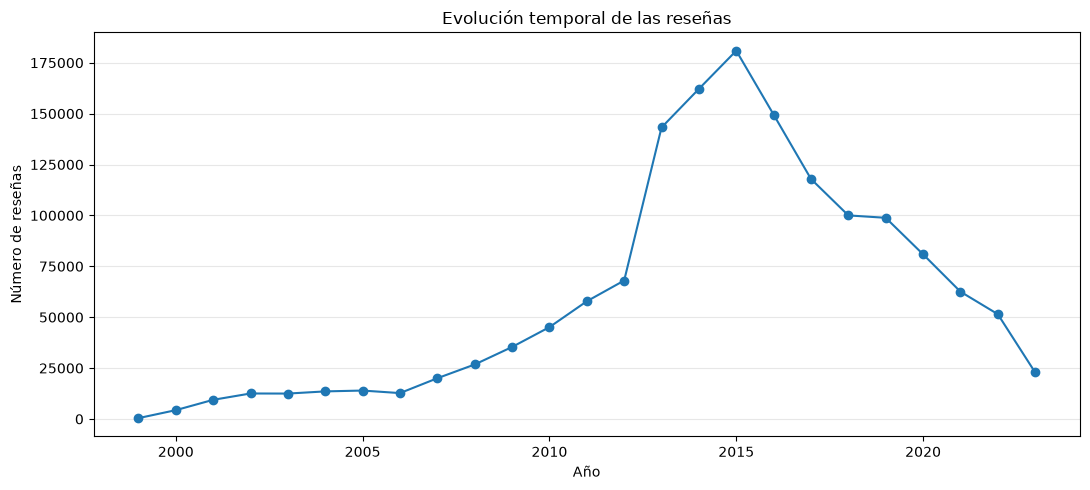

In [115]:
plt.figure(figsize=(11, 5))

plt.plot(
    resumen_temporal["Año"],
    resumen_temporal["Número de reseñas"],
    marker="o"
)

plt.title("Evolución temporal de las reseñas")
plt.xlabel("Año")
plt.ylabel("Número de reseñas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [116]:
# Comprobación última fecha
ultima_fecha = None

for archivo in archivos_resenas:
    bloque = pd.read_parquet(
        archivo,
        columns=["timestamp"]
    )

    fechas = pd.to_datetime(
        bloque["timestamp"],
        errors="coerce"
    )

    maxima_bloque = fechas.max()

    if ultima_fecha is None or maxima_bloque > ultima_fecha:
        ultima_fecha = maxima_bloque

print("Última fecha disponible:", ultima_fecha)

Última fecha disponible: 2023-09-10 12:20:10.107000
